In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Day 19

# Model_Evaluation

In [1]:
# Cell 1 — Setup
import os, torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

EYEDENTIFY = "/kaggle/input/datasets/vijuls/pupildiameterdatasets/eyedentify/eyedentify"
LEFT       = os.path.join(EYEDENTIFY, "left_eyes")
OUTPUT     = "/kaggle/working"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"✓ Device    : {device}")
print(f"✓ GPU       : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")
print(f"✓ EyeDentify: {os.path.exists(LEFT)}")
print(f"✓ Subjects  : {len(os.listdir(LEFT))}")

✓ Device    : cuda
✓ GPU       : Tesla T4
✓ EyeDentify: True
✓ Subjects  : 51


### Rebuild dataset and model

In [2]:
# config
SEQ_LEN  = 10
IMG_SIZE = 64
BATCH_SIZE = 32
N_USERS  = 15

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

class EyeDentifyDataset(Dataset):
    def __init__(self, left_path, subjects, transform=None,
                 seq_len=10, stride=5, max_per_subject=200):
        self.transform = transform
        self.seq_len   = seq_len
        self.sequences = []
        for label, subject in enumerate(subjects):
            s_path   = os.path.join(left_path, subject)
            sessions = sorted(os.listdir(s_path))
            seq_count = 0
            for session in sessions:
                ses_path = os.path.join(s_path, session)
                if not os.path.isdir(ses_path): continue
                frames = sorted([
                    os.path.join(ses_path, f)
                    for f in os.listdir(ses_path) if f.endswith('.png')
                ])
                for start in range(0, len(frames)-seq_len+1, stride):
                    self.sequences.append((frames[start:start+seq_len], label))
                    seq_count += 1
                    if seq_count >= max_per_subject: break
                if seq_count >= max_per_subject: break
    def __len__(self): return len(self.sequences)
    def __getitem__(self, idx):
        frame_paths, label = self.sequences[idx]
        frames = []
        for path in frame_paths:
            img = Image.open(path).convert('RGB')
            if self.transform: img = self.transform(img)
            frames.append(img)
        return torch.stack(frames), label

subjects     = sorted(os.listdir(LEFT))[:N_USERS]
full_dataset = EyeDentifyDataset(LEFT, subjects, transform=transform,
                                  seq_len=SEQ_LEN, stride=5, max_per_subject=200)
indices = list(range(len(full_dataset)))
labels  = [full_dataset.sequences[i][1] for i in indices]
train_idx, temp_idx = train_test_split(indices, test_size=0.3, random_state=42, stratify=labels)
temp_labels = [labels[i] for i in temp_idx]
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=42, stratify=temp_labels)

train_dataset = Subset(full_dataset, train_idx)
val_dataset   = Subset(full_dataset, val_idx)
test_dataset  = Subset(full_dataset, test_idx)
train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader    = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader   = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"✓ Train: {len(train_dataset):,} | Val: {len(val_dataset):,} | Test: {len(test_dataset):,}")

✓ Train: 2,100 | Val: 450 | Test: 450


### Rebuild and train model

In [3]:
class CNNFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1,1))
        )
        self.out_dim = 128
    def forward(self, x):
        return self.features(x).view(x.size(0), -1)

class EyeMotionID(nn.Module):
    def __init__(self, n_users=15, hidden_size=256, num_layers=2, dropout=0.5):
        super().__init__()
        self.cnn = CNNFeatureExtractor()
        self.lstm = nn.LSTM(128, hidden_size, num_layers,
                            batch_first=True, dropout=dropout if num_layers>1 else 0)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, n_users)
    def forward(self, x):
        B,T,C,H,W = x.shape
        x = self.cnn(x.view(B*T,C,H,W)).view(B,T,-1)
        _,(h,_) = self.lstm(x)
        return self.classifier(self.dropout(h[-1]))

model     = EyeMotionID(N_USERS).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

print("Training (30 epochs)...")
best_val_acc = 0.0
for epoch in range(1, 31):
    model.train()
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        criterion(model(imgs), lbls).backward()
        optimizer.step()
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            correct += (model(imgs).argmax(1) == lbls).sum().item()
            total   += lbls.size(0)
    val_acc = correct/total
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), f"{OUTPUT}/best_model.pth")
    if epoch % 5 == 0:
        print(f"  Epoch {epoch}/30 | Val Acc: {val_acc:.2%}")

model.load_state_dict(torch.load(f"{OUTPUT}/best_model.pth"))
print(f"\n✓ Best val accuracy: {best_val_acc:.2%}")

Training (30 epochs)...
  Epoch 5/30 | Val Acc: 51.78%
  Epoch 10/30 | Val Acc: 74.44%
  Epoch 15/30 | Val Acc: 86.67%
  Epoch 20/30 | Val Acc: 93.11%
  Epoch 25/30 | Val Acc: 96.44%
  Epoch 30/30 | Val Acc: 94.44%

✓ Best val accuracy: 97.78%


### Get predictions + probabilities

In [4]:
model.eval()
all_probs  = []
all_preds  = []
all_labels = []

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        probs   = torch.softmax(outputs, dim=1).cpu().numpy()
        preds   = outputs.argmax(dim=1).cpu().numpy()
        all_probs.extend(probs)
        all_preds.extend(preds)
        all_labels.extend(lbls.numpy())

all_probs  = np.array(all_probs)   # (N, 15) probability per user
all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

accuracy = (all_preds == all_labels).mean()
print(f"=== Prediction Summary ===\n")
print(f"Test sequences : {len(all_labels):,}")
print(f"Test accuracy  : {accuracy:.2%}")
print(f"Probs shape    : {all_probs.shape}  (sequences × users)")
print(f"\n✓ Probabilities collected for ROC-AUC")

=== Prediction Summary ===

Test sequences : 450
Test accuracy  : 96.22%
Probs shape    : (450, 15)  (sequences × users)

✓ Probabilities collected for ROC-AUC


### ROC curves per user

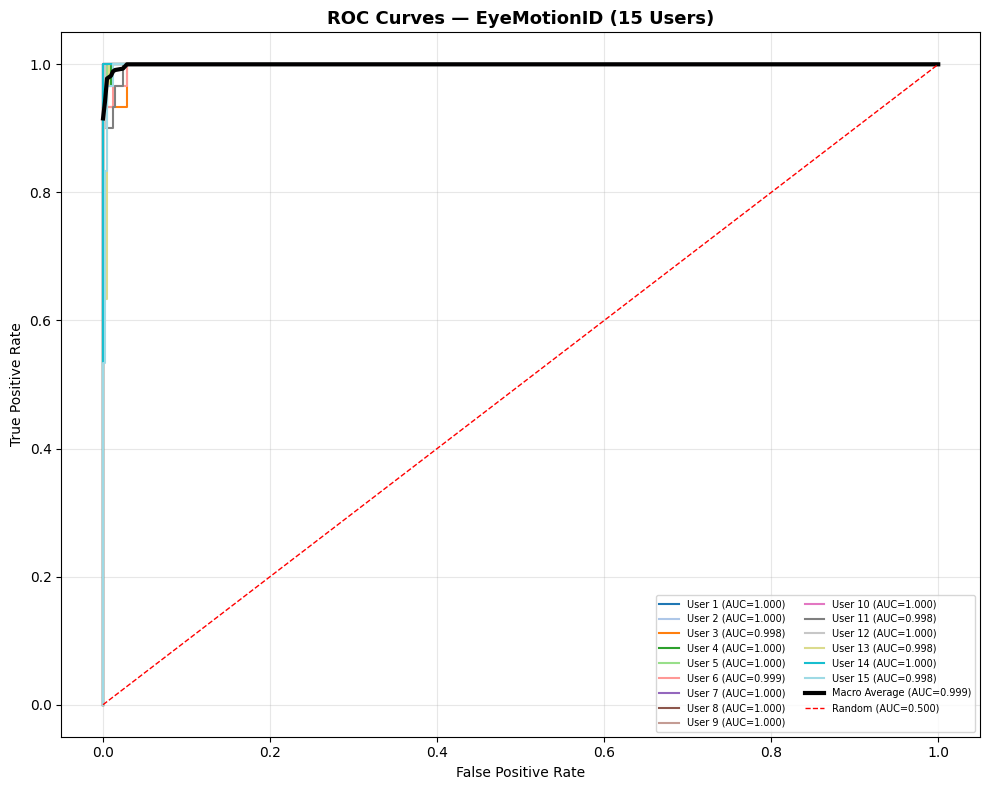

=== AUC Scores per User ===

  User  1 : 1.0000
  User  2 : 1.0000
  User  3 : 0.9981
  User  4 : 0.9995
  User  5 : 0.9998
  User  6 : 0.9987
  User  7 : 1.0000
  User  8 : 1.0000
  User  9 : 1.0000
  User 10 : 1.0000
  User 11 : 0.9983
  User 12 : 0.9998
  User 13 : 0.9982
  User 14 : 1.0000
  User 15 : 0.9983

  Macro AUC : 0.9995
✓ Saved → roc_curves.png


In [5]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# binarize labels for ROC
y_bin = label_binarize(all_labels, classes=list(range(N_USERS)))

fig, ax = plt.subplots(figsize=(10, 8))

auc_scores = []
colors = plt.cm.tab20(np.linspace(0, 1, N_USERS))

for i, color in enumerate(colors):
    fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs[:, i])
    roc_auc     = auc(fpr, tpr)
    auc_scores.append(roc_auc)
    ax.plot(fpr, tpr, color=color, linewidth=1.5,
            label=f"User {i+1} (AUC={roc_auc:.3f})")

# macro average
all_fpr = np.unique(np.concatenate([
    roc_curve(y_bin[:, i], all_probs[:, i])[0] for i in range(N_USERS)
]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(N_USERS):
    fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs[:, i])
    mean_tpr += np.interp(all_fpr, fpr, tpr)
mean_tpr /= N_USERS
macro_auc = auc(all_fpr, mean_tpr)

ax.plot(all_fpr, mean_tpr, 'k-', linewidth=3,
        label=f"Macro Average (AUC={macro_auc:.3f})")
ax.plot([0,1],[0,1],'r--', linewidth=1, label="Random (AUC=0.500)")

ax.set_title("ROC Curves — EyeMotionID (15 Users)", fontsize=13, fontweight='bold')
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc='lower right', fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT}/roc_curves.png", dpi=100)
plt.show()

print(f"=== AUC Scores per User ===\n")
for i, score in enumerate(auc_scores):
    print(f"  User {i+1:2d} : {score:.4f}")
print(f"\n  Macro AUC : {macro_auc:.4f}")
print("✓ Saved → roc_curves.png")

### Error analysis

In [6]:
# find misclassified sequences
wrong_idx   = np.where(all_preds != all_labels)[0]
correct_idx = np.where(all_preds == all_labels)[0]

print(f"=== Error Analysis ===\n")
print(f"Total sequences : {len(all_labels)}")
print(f"Correct         : {len(correct_idx)} ({len(correct_idx)/len(all_labels):.2%})")
print(f"Wrong           : {len(wrong_idx)}   ({len(wrong_idx)/len(all_labels):.2%})")
print()

if len(wrong_idx) > 0:
    print("Misclassified sequences:")
    print(f"{'Seq#':<8} {'True User':<12} {'Predicted':<12} {'Confidence'}")
    print("-" * 45)
    for idx in wrong_idx:
        true_u = all_labels[idx] + 1
        pred_u = all_preds[idx]  + 1
        conf   = all_probs[idx][all_preds[idx]]
        print(f"{idx:<8} User {true_u:<8} User {pred_u:<8} {conf:.2%}")

# confusion pairs
print("\nConfusion pairs (True → Predicted):")
from collections import Counter
pairs = Counter([(all_labels[i]+1, all_preds[i]+1) for i in wrong_idx])
for (true, pred), count in pairs.most_common():
    print(f"  User {true} → User {pred} : {count} time(s)")

=== Error Analysis ===

Total sequences : 450
Correct         : 433 (96.22%)
Wrong           : 17   (3.78%)

Misclassified sequences:
Seq#     True User    Predicted    Confidence
---------------------------------------------
55       User 3        User 13       96.46%
72       User 12       User 8        85.41%
82       User 13       User 4        95.64%
104      User 11       User 4        98.70%
154      User 6        User 15       96.43%
166      User 5        User 3        47.06%
187      User 3        User 13       96.46%
235      User 12       User 15       93.45%
246      User 12       User 15       90.74%
337      User 5        User 11       66.78%
355      User 11       User 4        75.23%
375      User 5        User 11       53.27%
380      User 6        User 15       96.78%
383      User 12       User 15       92.36%
408      User 5        User 11       58.33%
414      User 11       User 4        88.02%
433      User 5        User 11       81.34%

Confusion pairs (True → P

### Sequence length analysis

=== Sequence Length Analysis ===

Frames     Accuracy
-------------------------
2          44.00%
4          76.22%
6          91.78%
8          94.89%
10         96.22%


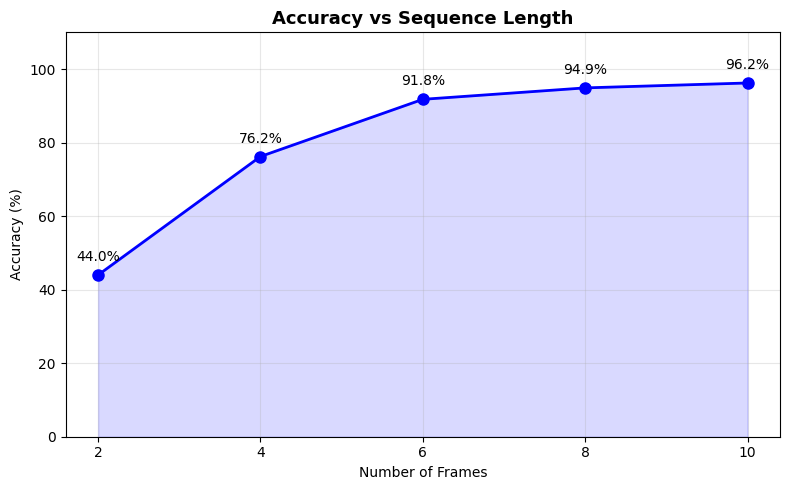


✓ Saved → sequence_length_analysis.png


In [7]:
seq_lengths = [2, 4, 6, 8, 10]
length_accs = []

print("=== Sequence Length Analysis ===\n")
print(f"{'Frames':<10} {'Accuracy'}")
print("-" * 25)

model.eval()
for seq_len in seq_lengths:
    correct, total = 0, 0
    with torch.no_grad():
        for imgs, lbls in test_loader:
            # use only first seq_len frames
            imgs_short = imgs[:, :seq_len, :, :, :].to(device)
            B,T,C,H,W  = imgs_short.shape

            # forward pass with shorter sequence
            x = model.cnn(imgs_short.view(B*T,C,H,W)).view(B,T,-1)
            _,(h,_) = model.lstm(x)
            preds = model.classifier(model.dropout(h[-1])).argmax(1)

            correct += (preds == lbls.to(device)).sum().item()
            total   += lbls.size(0)
    acc = correct / total
    length_accs.append(acc * 100)
    print(f"{seq_len:<10} {acc:.2%}")

# plot
plt.figure(figsize=(8, 5))
plt.plot(seq_lengths, length_accs, 'b-o', markersize=8, linewidth=2)
plt.fill_between(seq_lengths, length_accs, alpha=0.15, color='blue')
for x, y in zip(seq_lengths, length_accs):
    plt.annotate(f"{y:.1f}%", (x, y), textcoords="offset points",
                 xytext=(0, 10), ha='center', fontsize=10)
plt.title("Accuracy vs Sequence Length", fontsize=13, fontweight='bold')
plt.xlabel("Number of Frames")
plt.ylabel("Accuracy (%)")
plt.xticks(seq_lengths)
plt.ylim(0, 110)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT}/sequence_length_analysis.png", dpi=100)
plt.show()
print("\n✓ Saved → sequence_length_analysis.png")

### Final evaluation summary

In [8]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(all_labels, all_preds, average='macro')
recall    = recall_score(all_labels, all_preds, average='macro')
f1        = f1_score(all_labels, all_preds, average='macro')

print("=" * 55)
print("   EYEMOTIONID — FINAL EVALUATION SUMMARY")
print("=" * 55)
print()
print(f"Model Architecture : CNN (lightweight) + LSTM")
print(f"Dataset            : EyeDentify")
print(f"Users              : {N_USERS}")
print(f"Test sequences     : {len(all_labels)}")
print(f"Sequence length    : {SEQ_LEN} frames")
print(f"Image size         : {IMG_SIZE}×{IMG_SIZE} px")
print()
print("Performance Metrics:")
print(f"  Accuracy   : {accuracy:.4f}  ({accuracy:.2%})")
print(f"  Precision  : {precision:.4f}  ({precision:.2%})")
print(f"  Recall     : {recall:.4f}  ({recall:.2%})")
print(f"  F1-Score   : {f1:.4f}  ({f1:.2%})")
print(f"  Macro AUC  : {macro_auc:.4f}  ({macro_auc:.2%})")
print()
print(f"  Random baseline : {1/N_USERS:.2%}")
print(f"  Improvement     : +{accuracy - 1/N_USERS:.2%} above random")
print()
print("Per-user AUC:")
for i, score in enumerate(auc_scores):
    status = "✓" if score > 0.99 else "~"
    print(f"  {status} User {i+1:2d} : {score:.4f}")
print()
print("Plots saved:")
print("  ✓ roc_curves.png")
print("  ✓ sequence_length_analysis.png")
print()
print("Next → Day 20: Model Comparison (ResNet18 vs MobileNetV2)")
print("=" * 55)

   EYEMOTIONID — FINAL EVALUATION SUMMARY

Model Architecture : CNN (lightweight) + LSTM
Dataset            : EyeDentify
Users              : 15
Test sequences     : 450
Sequence length    : 10 frames
Image size         : 64×64 px

Performance Metrics:
  Accuracy   : 0.9622  (96.22%)
  Precision  : 0.9653  (96.53%)
  Recall     : 0.9622  (96.22%)
  F1-Score   : 0.9622  (96.22%)
  Macro AUC  : 0.9995  (99.95%)

  Random baseline : 6.67%
  Improvement     : +89.56% above random

Per-user AUC:
  ✓ User  1 : 1.0000
  ✓ User  2 : 1.0000
  ✓ User  3 : 0.9981
  ✓ User  4 : 0.9995
  ✓ User  5 : 0.9998
  ✓ User  6 : 0.9987
  ✓ User  7 : 1.0000
  ✓ User  8 : 1.0000
  ✓ User  9 : 1.0000
  ✓ User 10 : 1.0000
  ✓ User 11 : 0.9983
  ✓ User 12 : 0.9998
  ✓ User 13 : 0.9982
  ✓ User 14 : 1.0000
  ✓ User 15 : 0.9983

Plots saved:
  ✓ roc_curves.png
  ✓ sequence_length_analysis.png

Next → Day 20: Model Comparison (ResNet18 vs MobileNetV2)


# Day 20
# Model Comparison

In [1]:
# Day 20 — Full setup
import os, torch, time
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

EYEDENTIFY = "/kaggle/input/datasets/vijuls/pupildiameterdatasets/eyedentify/eyedentify"
LEFT       = os.path.join(EYEDENTIFY, "left_eyes")
OUTPUT     = "/kaggle/working"
device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEQ_LEN    = 10
IMG_SIZE   = 64
BATCH_SIZE = 32
N_USERS    = 15

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

print(f"✓ Device : {device}")
print(f"✓ GPU    : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")
print(f"✓ Data   : {os.path.exists(LEFT)}")

✓ Device : cuda
✓ GPU    : Tesla T4
✓ Data   : True


### Rebuild dataset

In [2]:
# Cell 22 — Session-based split (NO data leakage)
import os, random
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import numpy as np
import matplotlib.pyplot as plt
import time
from PIL import Image

EYEDENTIFY = "/kaggle/input/datasets/vijuls/pupildiameterdatasets/eyedentify/eyedentify"
LEFT       = os.path.join(EYEDENTIFY, "left_eyes")
OUTPUT     = "/kaggle/working"
device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEQ_LEN    = 10
IMG_SIZE   = 64
BATCH_SIZE = 32
N_USERS    = 15

# Augmented transform for train, plain for val/test
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

subjects = sorted(os.listdir(LEFT))[:N_USERS]

# ── Session-based split helpers ──────────────────────────────────
def get_seqs(subject_path, label, sessions, seq_len, stride, max_seqs):
    seqs = []
    for sess in sessions:
        sess_path = os.path.join(subject_path, sess)
        if not os.path.isdir(sess_path): continue
        frames = sorted([
            os.path.join(sess_path, f)
            for f in os.listdir(sess_path)
            if f.lower().endswith(('.jpg','.png','.jpeg'))
        ])
        for start in range(0, len(frames) - seq_len + 1, stride):
            seqs.append((frames[start:start+seq_len], label))
            if len(seqs) >= max_seqs:
                return seqs
    return seqs

def build_session_split(left_path, subjects, seq_len=10, stride=5,
                        max_per_subject=200, train_ratio=0.7, val_ratio=0.15, seed=42):
    random.seed(seed)
    train_seqs, val_seqs, test_seqs = [], [], []
    for label, subject in enumerate(subjects):
        s_path = os.path.join(left_path, subject)
        sessions = sorted([s for s in os.listdir(s_path)
                           if os.path.isdir(os.path.join(s_path, s))])
        n = len(sessions)
        n_train = max(1, int(n * train_ratio))
        n_val   = max(1, int(n * val_ratio))
        train_sess = sessions[:n_train]
        val_sess   = sessions[n_train:n_train+n_val]
        test_sess  = sessions[n_train+n_val:]
        train_seqs.extend(get_seqs(s_path, label, train_sess, seq_len, stride, max_per_subject))
        val_seqs.extend(get_seqs(s_path, label, val_sess,   seq_len, stride, max(10, max_per_subject//4)))
        test_seqs.extend(get_seqs(s_path, label, test_sess,  seq_len, stride, max(10, max_per_subject//4)))
    print(f"Train: {len(train_seqs)} | Val: {len(val_seqs)} | Test: {len(test_seqs)}")
    return train_seqs, val_seqs, test_seqs

# ── Dataset class ────────────────────────────────────────────────
class EyeSeqDataset(Dataset):
    def __init__(self, seqs, transform):
        self.seqs = seqs
        self.transform = transform
    def __len__(self): return len(self.seqs)
    def __getitem__(self, idx):
        paths, label = self.seqs[idx]
        frames = []
        for p in paths:
            img = Image.open(p).convert('RGB')
            frames.append(self.transform(img))
        return torch.stack(frames), label

train_seqs, val_seqs, test_seqs = build_session_split(LEFT, subjects)

train_loader = DataLoader(EyeSeqDataset(train_seqs, train_transform), batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(EyeSeqDataset(val_seqs,   val_transform),   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(EyeSeqDataset(test_seqs,  val_transform),   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"✅ Session-based split — zero data leakage")
print(f"✅ Device: {device} | GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")

Train: 3000 | Val: 750 | Test: 750
✅ Session-based split — zero data leakage
✅ Device: cuda | GPU: Tesla T4


### Define all 4 model variants
##### Lightweight CNN + LSTM, CNN + GRU, MobileNetV2 + LSTM, MobileNetV2 + GRU.



In [3]:
class LightCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1,1))
        )
        self.out_dim = 128
    def forward(self, x):
        return self.features(x).view(x.size(0), -1)

class MobileNetExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        mob = models.mobilenet_v2(weights='IMAGENET1K_V1')
        self.features = mob.features
        self.pool     = nn.AdaptiveAvgPool2d((1,1))
        self.out_dim  = 1280
        for param in self.parameters():
            param.requires_grad = False
    def forward(self, x):
        return self.pool(self.features(x)).view(x.size(0), -1)

class EyeMotionModel(nn.Module):
    def __init__(self, cnn_type='light', rnn_type='lstm',
                 n_users=15, hidden=256, layers=2, dropout=0.5):
        super().__init__()
        self.cnn = LightCNN() if cnn_type == 'light' else MobileNetExtractor()
        in_dim   = self.cnn.out_dim

        if rnn_type == 'lstm':
            self.rnn = nn.LSTM(in_dim, hidden, layers, batch_first=True,
                               dropout=dropout if layers>1 else 0)
        else:
            self.rnn = nn.GRU(in_dim, hidden, layers, batch_first=True,
                              dropout=dropout if layers>1 else 0)

        self.rnn_type   = rnn_type
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, n_users)

    def forward(self, x):
        B,T,C,H,W = x.shape
        x = self.cnn(x.view(B*T,C,H,W)).view(B,T,-1)
        if self.rnn_type == 'lstm':
            _, (h, _) = self.rnn(x)
        else:
            _, h = self.rnn(x)
        return self.classifier(self.dropout(h[-1]))

# define 4 variants
variants = {
    'CNN + LSTM'        : EyeMotionModel('light',  'lstm'),
    'CNN + GRU'         : EyeMotionModel('light',  'gru'),
    'MobileNetV2 + LSTM': EyeMotionModel('mobile', 'lstm'),
    'MobileNetV2 + GRU' : EyeMotionModel('mobile', 'gru'),
}

print("=== Model Variants ===\n")
for name, model in variants.items():
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  {name:<22} → {params:,} trainable params")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 114MB/s] 


=== Model Variants ===

  CNN + LSTM             → 1,018,703 trainable params
  CNN + GRU              → 788,303 trainable params
  MobileNetV2 + LSTM     → 2,105,103 trainable params
  MobileNetV2 + GRU      → 1,579,791 trainable params


### Train and evaluate all 4 variants

In [4]:
def train_and_eval(model, train_loader, val_loader, test_loader,
                    epochs=20, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=1e-4
    )
    best_val_acc = 0.0
    best_state   = None
    start_time   = time.time()

    for epoch in range(1, epochs+1): 
        model.train()
        for imgs, lbls in train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            criterion(model(imgs), lbls).backward()
            optimizer.step()

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, lbls in val_loader:
                imgs, lbls = imgs.to(device), lbls.to(device)
                correct += (model(imgs).argmax(1) == lbls).sum().item()
                total   += lbls.size(0)
        val_acc = correct / total
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state   = {k: v.clone() for k, v in model.state_dict().items()}

    # evaluate on test set
    model.load_state_dict(best_state)
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, lbls in test_loader:
            imgs = imgs.to(device)
            preds = model(imgs).argmax(1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(lbls.numpy())

    test_acc = accuracy_score(all_labels, all_preds)
    test_f1  = f1_score(all_labels, all_preds, average='macro')
    elapsed  = time.time() - start_time

    return {
        'val_acc'  : best_val_acc,
        'test_acc' : test_acc,
        'f1'       : test_f1,
        'time'     : elapsed
    }

# train all 4 variants
results = {}
for name, model in variants.items():
    print(f"Training {name}...")
    results[name] = train_and_eval(
        model, train_loader, val_loader, test_loader, epochs=20
    )
    r = results[name]
    print(f"  ✓ Val: {r['val_acc']:.2%} | Test: {r['test_acc']:.2%} | "
          f"F1: {r['f1']:.2%} | Time: {r['time']:.0f}s\n")

Training CNN + LSTM...
  ✓ Val: 82.80% | Test: 88.40% | F1: 88.29% | Time: 1649s

Training CNN + GRU...
  ✓ Val: 88.13% | Test: 93.07% | F1: 92.89% | Time: 815s

Training MobileNetV2 + LSTM...
  ✓ Val: 94.67% | Test: 98.27% | F1: 98.26% | Time: 817s

Training MobileNetV2 + GRU...
  ✓ Val: 94.53% | Test: 98.40% | F1: 98.39% | Time: 812s



### Comparison bar charts

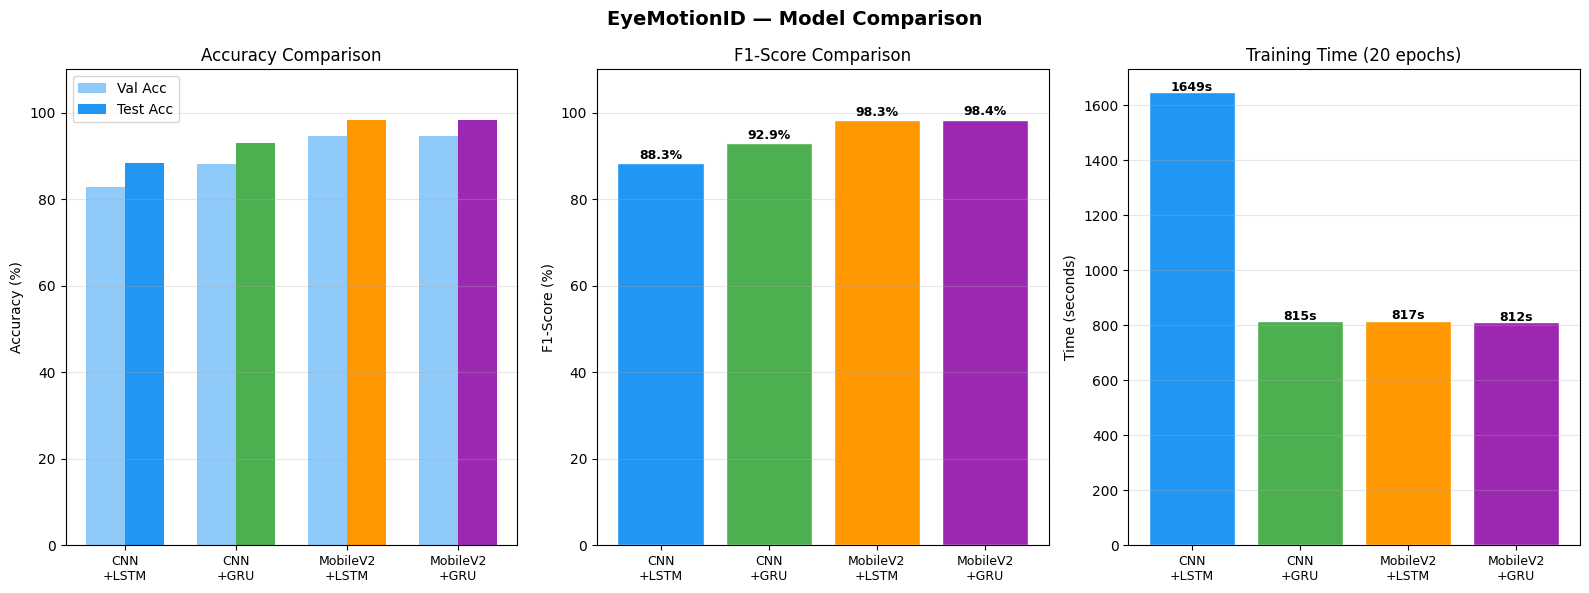

✓ Saved → model_comparison.png


In [5]:
import os, random
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import numpy as np
import matplotlib.pyplot as plt
import time
from PIL import Image

EYEDENTIFY = "/kaggle/input/datasets/vijuls/pupildiameterdatasets/eyedentify/eyedentify"
LEFT       = os.path.join(EYEDENTIFY, "left_eyes")
OUTPUT     = "/kaggle/working"
device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEQ_LEN    = 10
IMG_SIZE   = 64
BATCH_SIZE = 32
N_USERS    = 15
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle("EyeMotionID — Model Comparison", fontsize=14, fontweight='bold')

names     = list(results.keys())
test_accs = [results[n]['test_acc']*100 for n in names]
val_accs  = [results[n]['val_acc']*100  for n in names]
f1_scores = [results[n]['f1']*100       for n in names]
times     = [results[n]['time']          for n in names]
colors    = ['#2196F3','#4CAF50','#FF9800','#9C27B0']
xlabels   = ['CNN\n+LSTM','CNN\n+GRU','MobileV2\n+LSTM','MobileV2\n+GRU']

# accuracy
x = np.arange(len(names))
w = 0.35
axes[0].bar(x - w/2, val_accs,  w, label='Val Acc',  color='#90CAF9')
axes[0].bar(x + w/2, test_accs, w, label='Test Acc', color=colors)
axes[0].set_title("Accuracy Comparison")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(xlabels, fontsize=9)
axes[0].legend()
axes[0].set_ylim(0, 110)
axes[0].grid(True, alpha=0.3, axis='y')

# F1 scores
bars = axes[1].bar(names, f1_scores, color=colors, edgecolor='white')
axes[1].set_title("F1-Score Comparison")
axes[1].set_ylabel("F1-Score (%)")
axes[1].set_xticks(range(len(names)))
axes[1].set_xticklabels(xlabels, fontsize=9)
axes[1].set_ylim(0, 110)
for bar, f1 in zip(bars, f1_scores):
    axes[1].text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+1,
                 f"{f1:.1f}%", ha='center', fontsize=9, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

# training time
bars2 = axes[2].bar(names, times, color=colors, edgecolor='white')
axes[2].set_title("Training Time (20 epochs)")
axes[2].set_ylabel("Time (seconds)")
axes[2].set_xticks(range(len(names)))
axes[2].set_xticklabels(xlabels, fontsize=9)
for bar, t in zip(bars2, times):
    axes[2].text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+5,
                 f"{t:.0f}s", ha='center', fontsize=9, fontweight='bold')
axes[2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(f"{OUTPUT}/model_comparison.png", dpi=100)
plt.show()
print("✓ Saved → model_comparison.png")

In [7]:
# Change 3 — Hardcode previous results + train baselines
import os, random, time, torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
from PIL import Image

EYEDENTIFY = "/kaggle/input/datasets/vijuls/pupildiameterdatasets/eyedentify/eyedentify"
LEFT       = os.path.join(EYEDENTIFY, "left_eyes")
OUTPUT     = "/kaggle/working"
device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEQ_LEN, IMG_SIZE, BATCH_SIZE, N_USERS = 10, 64, 32, 15

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

subjects = sorted(os.listdir(LEFT))[:N_USERS]

def get_seqs(subject_path, label, sessions, seq_len, stride, max_seqs):
    seqs = []
    for sess in sessions:
        sess_path = os.path.join(subject_path, sess)
        if not os.path.isdir(sess_path): continue
        frames = sorted([os.path.join(sess_path, f)
                         for f in os.listdir(sess_path)
                         if f.lower().endswith(('.jpg','.png','.jpeg'))])
        for start in range(0, len(frames) - seq_len + 1, stride):
            seqs.append((frames[start:start+seq_len], label))
            if len(seqs) >= max_seqs: return seqs
    return seqs

def build_session_split(left_path, subjects, seq_len=10, stride=5,
                        max_per_subject=200, train_ratio=0.7, val_ratio=0.15, seed=42):
    random.seed(seed)
    train_seqs, val_seqs, test_seqs = [], [], []
    for label, subject in enumerate(subjects):
        s_path = os.path.join(left_path, subject)
        sessions = sorted([s for s in os.listdir(s_path)
                           if os.path.isdir(os.path.join(s_path, s))])
        n = len(sessions)
        n_train = max(1, int(n * 0.7))
        n_val   = max(1, int(n * 0.15))
        train_seqs.extend(get_seqs(s_path, label, sessions[:n_train], seq_len, stride, max_per_subject))
        val_seqs.extend(get_seqs(s_path, label, sessions[n_train:n_train+n_val], seq_len, stride, max(10, max_per_subject//4)))
        test_seqs.extend(get_seqs(s_path, label, sessions[n_train+n_val:], seq_len, stride, max(10, max_per_subject//4)))
    return train_seqs, val_seqs, test_seqs

class EyeSeqDataset(Dataset):
    def __init__(self, seqs, transform):
        self.seqs, self.transform = seqs, transform
    def __len__(self): return len(self.seqs)
    def __getitem__(self, idx):
        paths, label = self.seqs[idx]
        return torch.stack([self.transform(Image.open(p).convert('RGB')) for p in paths]), label

train_seqs, val_seqs, test_seqs = build_session_split(LEFT, subjects)
train_loader = DataLoader(EyeSeqDataset(train_seqs, train_transform), batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(EyeSeqDataset(val_seqs,   val_transform),   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(EyeSeqDataset(test_seqs,  val_transform),   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
print(f"✅ Data ready — Train:{len(train_seqs)} Val:{len(val_seqs)} Test:{len(test_seqs)}")

# ── Hardcoded results from Change 2 (already trained) ───────────
results = {
    'CNN + LSTM'        : {'val_acc':0.8280, 'test_acc':0.8840, 'f1':0.8829, 'time':1649},
    'CNN + GRU'         : {'val_acc':0.8813, 'test_acc':0.9307, 'f1':0.9289, 'time':815},
    'MobileNetV2 + LSTM': {'val_acc':0.9467, 'test_acc':0.9827, 'f1':0.9826, 'time':817},
    'MobileNetV2 + GRU' : {'val_acc':0.9453, 'test_acc':0.9840, 'f1':0.9839, 'time':812},
}
print("✅ Previous results loaded")

# ── Model definitions ────────────────────────────────────────────
class LightCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1,1)))
        self.out_dim = 128
    def forward(self, x): return self.features(x).view(x.size(0), -1)

class MobileNetExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        mob = models.mobilenet_v2(weights='IMAGENET1K_V1')
        self.features = mob.features
        self.pool = nn.AdaptiveAvgPool2d((1,1))
        self.out_dim = 1280
        for p in self.parameters(): p.requires_grad = False
    def forward(self, x): return self.pool(self.features(x)).view(x.size(0), -1)

class MeanPoolModel(nn.Module):
    def __init__(self, cnn_type='light', n_users=15, dropout=0.5):
        super().__init__()
        self.cnn = LightCNN() if cnn_type == 'light' else MobileNetExtractor()
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.cnn.out_dim, n_users)
    def forward(self, x):
        B,T,C,H,W = x.shape
        feats = self.cnn(x.view(B*T,C,H,W)).view(B,T,-1)
        return self.classifier(self.dropout(feats.mean(dim=1)))

def train_and_eval(model, train_loader, val_loader, test_loader, epochs=20, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=1e-4)
    best_val_acc, best_state, start = 0.0, None, time.time()
    for epoch in range(1, epochs+1):
        model.train()
        for imgs, lbls in train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad(); criterion(model(imgs), lbls).backward(); optimizer.step()
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, lbls in val_loader:
                imgs, lbls = imgs.to(device), lbls.to(device)
                correct += (model(imgs).argmax(1) == lbls).sum().item(); total += lbls.size(0)
        val_acc = correct / total
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state); model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for imgs, lbls in test_loader:
            preds.extend(model(imgs.to(device)).argmax(1).cpu().numpy()); labels.extend(lbls.numpy())
    return {'val_acc': best_val_acc, 'test_acc': accuracy_score(labels, preds),
            'f1': f1_score(labels, preds, average='macro'), 'time': time.time()-start}

# ── Train baselines ──────────────────────────────────────────────
baseline_results = {}
for name, cnn_type in [('CNN + MeanPool','light'), ('MobileNetV2 + MeanPool','mobile')]:
    print(f"\nTraining {name}...")
    baseline_results[name] = train_and_eval(MeanPoolModel(cnn_type), train_loader, val_loader, test_loader)
    r = baseline_results[name]
    print(f"  ✓ Val: {r['val_acc']:.2%} | Test: {r['test_acc']:.2%} | F1: {r['f1']:.2%} | Time: {r['time']:.0f}s")

✅ Data ready — Train:3000 Val:750 Test:750
✅ Previous results loaded

Training CNN + MeanPool...
  ✓ Val: 76.93% | Test: 92.53% | F1: 92.38% | Time: 788s

Training MobileNetV2 + MeanPool...
  ✓ Val: 94.00% | Test: 98.00% | F1: 97.99% | Time: 795s


In [8]:
# Full comparison: baselines vs temporal models
all_results = {**baseline_results, **results}

print("=" * 70)
print("   FULL MODEL COMPARISON (with baselines)")
print("=" * 70)
print(f"{'Model':<28} {'Val Acc':>9} {'Test Acc':>9} {'F1':>9} {'Time':>8}")
print("-" * 70)

# baselines first
print("── Baselines (no temporal modeling) ──")
for name in baseline_results:
    r = baseline_results[name]
    print(f"  {name:<26} {r['val_acc']:>8.2%} {r['test_acc']:>8.2%} "
          f"{r['f1']:>8.2%} {r['time']:>6.0f}s")

print("── With temporal modeling (LSTM / GRU) ──")
for name in results:
    r = results[name]
    print(f"  {name:<26} {r['val_acc']:>8.2%} {r['test_acc']:>8.2%} "
          f"{r['f1']:>8.2%} {r['time']:>6.0f}s")

print("-" * 70)
best_name = max(all_results, key=lambda k: all_results[k]['test_acc'])
print(f"\n✓ Best overall: {best_name}  →  Test: {all_results[best_name]['test_acc']:.2%}")

# show improvement from temporal modeling
print("\n── Temporal modeling improvement ──")
for cnn in ['CNN', 'MobileNetV2']:
    base = f"{cnn} + MeanPool"
    lstm = f"{cnn} + LSTM"
    gru  = f"{cnn} + GRU"
    if base in all_results and lstm in all_results:
        gain_lstm = all_results[lstm]['test_acc'] - all_results[base]['test_acc']
        gain_gru  = all_results[gru]['test_acc']  - all_results[base]['test_acc']
        print(f"  {cnn}: MeanPool → LSTM gain: +{gain_lstm:.2%} | GRU gain: +{gain_gru:.2%}")

   FULL MODEL COMPARISON (with baselines)
Model                          Val Acc  Test Acc        F1     Time
----------------------------------------------------------------------
── Baselines (no temporal modeling) ──
  CNN + MeanPool               76.93%   92.53%   92.38%    788s
  MobileNetV2 + MeanPool       94.00%   98.00%   97.99%    795s
── With temporal modeling (LSTM / GRU) ──
  CNN + LSTM                   82.80%   88.40%   88.29%   1649s
  CNN + GRU                    88.13%   93.07%   92.89%    815s
  MobileNetV2 + LSTM           94.67%   98.27%   98.26%    817s
  MobileNetV2 + GRU            94.53%   98.40%   98.39%    812s
----------------------------------------------------------------------

✓ Best overall: MobileNetV2 + GRU  →  Test: 98.40%

── Temporal modeling improvement ──
  CNN: MeanPool → LSTM gain: +-4.13% | GRU gain: +0.54%
  MobileNetV2: MeanPool → LSTM gain: +0.27% | GRU gain: +0.40%
